# Momentum with Different Polynomials — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/05-deep-learning-with-pytorch/notebooks/momentum-with-different-polynomials.ipynb) · [Course notes](../../../courses/05-deep-learning-with-pytorch/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


<h1>Momentum with Different Polynomials</h1>


<h3>Objectives</h3>    

<ul>
    <li>Learn how momentum can improve the results of optimization issues such as saddle points, local minima, and noise</li>


<p>Estimated Time Needed: <b>25 mins</b></p>


<h2>Table of Contents</h2>
<p>In this lab, you will deal with several problems associated with optimization and see how momentum can improve your results.</p>
<ul>
    <li><a href="#Preparation">Preparation</a></li>
    <li><a href="#Saddle-Points">Saddle Points</a></li>
    <li><a href="#Local-Minima">Local Minima</a></li>
    <li><a href="#Noise"> Noise </a></li>
    <li><a href="#Practice"> Practice </a></li>
</ul>

<hr>


<h2>Preparation</h2>


Import the following libraries that you'll use for this lab:


In [2]:
import torch
import torch.nn as nn
import matplotlib.pylab as plt
import numpy as np
torch.manual_seed(0)

Matplotlib is building the font cache; this may take a moment.


This function will plot a cubic function and the parameter values obtained via Gradient Descent.


In [3]:
def plot_cubic(w, optimizer):
    LOSS = []
    W = torch.arange(-4, 4, 0.1)
    for w.state_dict()['linear.weight'][0] in W:
        LOSS.append(cubic(w(torch.tensor([[1.0]]))).item())
    w.state_dict()['linear.weight'][0] = 4.0
    n_epochs = 2
    parameter = []
    loss_list = []
    for n in range(n_epochs):
        optimizer.zero_grad()
        loss = cubic(w(torch.tensor([[1.0]])))
        loss_list.append(loss)
        parameter.append(w.state_dict()['linear.weight'][0].detach().data.item())
        loss.backward()
        optimizer.step()
    plt.plot(parameter, [loss.detach().numpy().flatten() for loss in loss_list], 'ro', label='parameter values')
    plt.plot(W.numpy(), LOSS, label='objective function')
    plt.xlabel('w')
    plt.ylabel('l(w)')
    plt.legend()

This function will plot a 4th order function and the parameter values obtained via Gradient Descent. You can also add Gaussian noise with a standard deviation determined by the parameter <code>std</code>.


In [4]:
def plot_fourth_order(w, optimizer, std=0, color='r', paramlabel='parameter values', objfun=True):
    W = torch.arange(-4, 6, 0.1)
    LOSS = []
    for w.state_dict()['linear.weight'][0] in W:
        LOSS.append(fourth_order(w(torch.tensor([[1.0]]))).item())
    w.state_dict()['linear.weight'][0] = 6
    n_epochs = 2
    parameter = []
    loss_list = []
    for n in range(n_epochs):
        optimizer.zero_grad()
        loss = fourth_order(w(torch.tensor([[1.0]]))) + std * torch.randn(1, 1)
        loss_list.append(loss)
        parameter.append(w.state_dict()['linear.weight'][0].detach().data.item())
        loss.backward()
        optimizer.step()
    if objfun:
        plt.plot(W.numpy(), LOSS, label='objective function')
    plt.plot(parameter, [loss.detach().numpy().flatten() for loss in loss_list], 'ro', label='paramlabel', color=color)
    plt.xlabel('w')
    plt.ylabel('l(w)')
    plt.legend()

This is a custom module. It will behave like a single parameter value. We do it this way so we can use PyTorch's build-in optimizers .


In [5]:
class one_param(nn.Module):

    def __init__(self, input_size, output_size):
        super(one_param, self).__init__()
        self.linear = nn.Linear(input_size, output_size, bias=False)

    def forward(self, x):
        yhat = self.linear(x)
        return yhat

We create an object <code>w</code>, when we call the object with an input of one, it will behave like an individual parameter value. i.e <code>w(1)</code> is analogous to $w$ 


In [6]:
w = one_param(1, 1)

<!--Empty Space for separating topics-->


<h2>Saddle Points</h2>


Let's create a cubic function with Saddle points 


In [7]:
def cubic(yhat):
    out = yhat ** 3
    return out

We create an optimizer with no momentum term 


In [8]:
optimizer = torch.optim.SGD(w.parameters(), lr=0.01, momentum=0)

We run several iterations of stochastic gradient descent and plot the results. We see the parameter values get stuck in the saddle point.


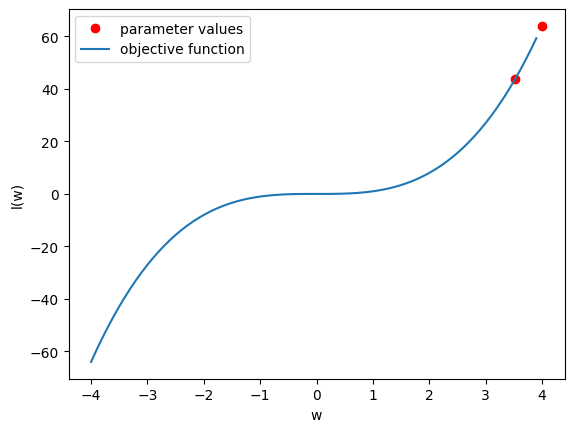

In [9]:
plot_cubic(w, optimizer)

we create an optimizer with momentum term of 0.9


In [10]:
optimizer = torch.optim.SGD(w.parameters(), lr=0.01, momentum=0.9)

We run several iterations of stochastic gradient descent with momentum and plot the results. We see the parameter values do not get stuck in the saddle point.


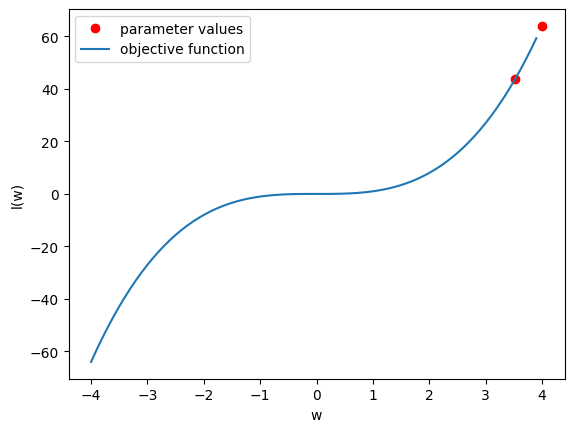

In [11]:
plot_cubic(w, optimizer)

<!--Empty Space for separating topics-->


<h2>Local Minima</h2>


In this section, we will create a fourth order polynomial with a local minimum at <i>4</i> and a global minimum a <i>-2</i>. We will then see how the momentum parameter affects convergence to a global minimum. The fourth order polynomial is given by:


In [12]:
def fourth_order(yhat):
    out = torch.mean(2 * yhat ** 4 - 9 * yhat ** 3 - 21 * yhat ** 2 + 88 * yhat + 48)
    return out

We create an optimizer with no momentum term. We run several iterations of stochastic gradient descent and plot the results. We see the parameter values get stuck in the local minimum.


/var/folders/vl/bmn2g4756lb2syhg08c_mv040000gn/T/ipykernel_73023/3620876191.py:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  plt.plot(parameter, [loss.detach().numpy().flatten() for loss in loss_list], 'ro', label='paramlabel', color=color)


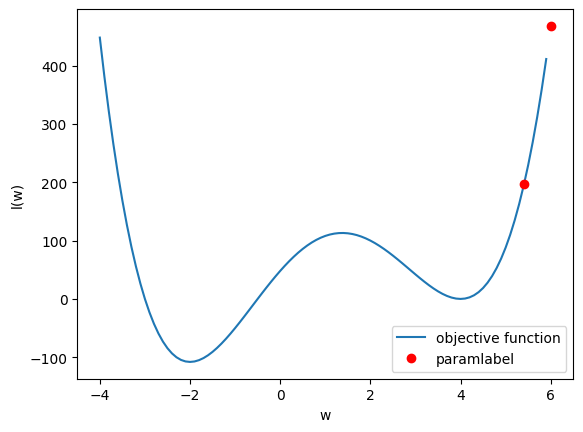

In [13]:
optimizer = torch.optim.SGD(w.parameters(), lr=0.001)
plot_fourth_order(w, optimizer)

We create an optimizer with a  momentum term of 0.9. We run several iterations of stochastic gradient descent and plot the results. We see the parameter values reach a global minimum.


/var/folders/vl/bmn2g4756lb2syhg08c_mv040000gn/T/ipykernel_73023/3620876191.py:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  plt.plot(parameter, [loss.detach().numpy().flatten() for loss in loss_list], 'ro', label='paramlabel', color=color)


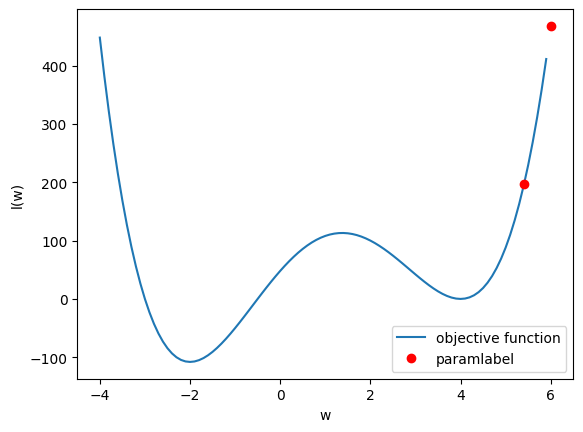

In [14]:
optimizer = torch.optim.SGD(w.parameters(), lr=0.001, momentum=0.9)
plot_fourth_order(w, optimizer)

<!--Empty Space for separating topics-->


<h2>Noise</h2>


In this section, we will create a fourth order polynomial with a local minimum at 4 and a global minimum a -2, but we will add noise to the function when the Gradient is calculated. We will then see how the momentum parameter affects convergence to a global minimum. 


with no momentum, we get stuck in a local minimum 


/var/folders/vl/bmn2g4756lb2syhg08c_mv040000gn/T/ipykernel_73023/3620876191.py:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  plt.plot(parameter, [loss.detach().numpy().flatten() for loss in loss_list], 'ro', label='paramlabel', color=color)


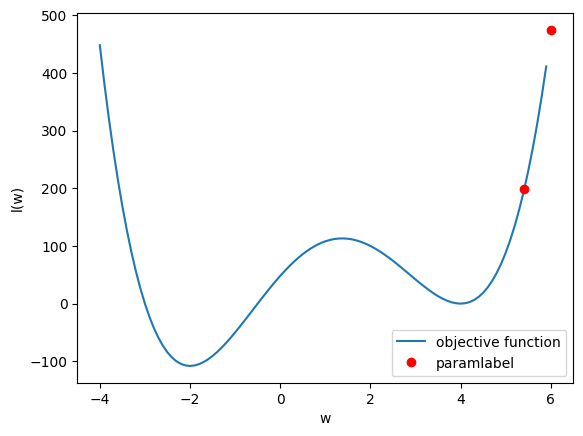

In [15]:
optimizer = torch.optim.SGD(w.parameters(), lr=0.001)
plot_fourth_order(w, optimizer, std=10)

with  momentum, we get to the global  minimum 


/var/folders/vl/bmn2g4756lb2syhg08c_mv040000gn/T/ipykernel_73023/3620876191.py:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  plt.plot(parameter, [loss.detach().numpy().flatten() for loss in loss_list], 'ro', label='paramlabel', color=color)


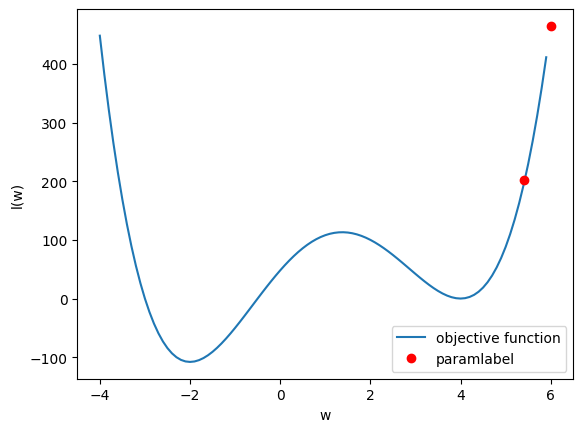

In [16]:
optimizer = torch.optim.SGD(w.parameters(), lr=0.001, momentum=0.9)
plot_fourth_order(w, optimizer, std=10)

<!--Empty Space for separating topics-->


<h3>Practice</h3>


Create two <code> SGD</code>  objects with a learning rate of <code> 0.001</code>. Use the default momentum parameter value  for one and a value of <code> 0.9</code> for the second. Use the function <code>plot_fourth_order</code> with an <code>std=100</code>, to plot the different steps of each. Make sure you run the function on two independent cells.


/var/folders/vl/bmn2g4756lb2syhg08c_mv040000gn/T/ipykernel_73023/3620876191.py:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  plt.plot(parameter, [loss.detach().numpy().flatten() for loss in loss_list], 'ro', label='paramlabel', color=color)


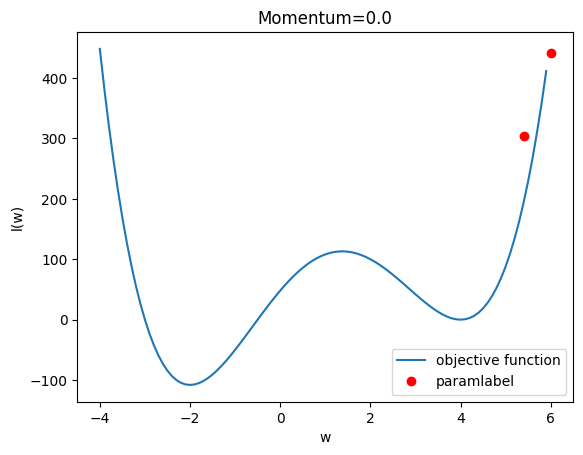

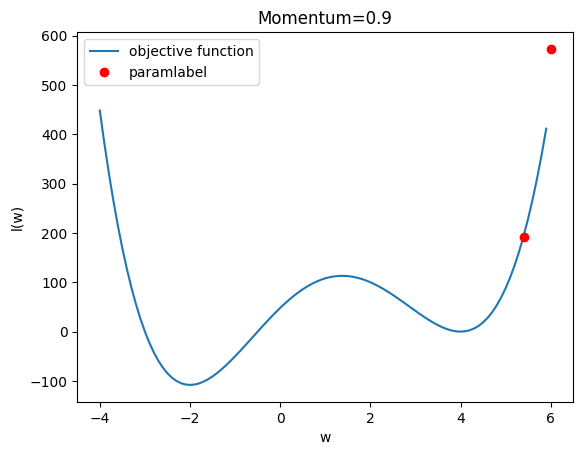

In [17]:
for momentum in [0.0, 0.9]:
    parameter_model = one_param(1, 1)
    optimizer = torch.optim.SGD(parameter_model.parameters(), lr=0.001, momentum=momentum)
    plt.figure()
    plot_fourth_order(parameter_model, optimizer, std=100)
    plt.title(f'Momentum={momentum}')
    plt.show()

Double-click <b>here</b> for the solution.

<!-- 
optimizer1 = torch.optim.SGD(w.parameters(), lr = 0.001)
plot_fourth_order(w, optimizer1, std = 100, color = 'black', paramlabel = 'parameter values with optimizer 1')

optimizer2 = torch.optim.SGD(w.parameters(), lr = 0.001, momentum = 0.9)
plot_fourth_order(w, optimizer2, std = 100, color = 'red', paramlabel = 'parameter values with optimizer 2', objfun = False)
 -->


<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a> 


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-09-23  | 2.0  | Srishti  |  Migrated Lab to Markdown and added to course repo in GitLab |



<hr>
-->

## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
